# MEWpy Simulation

This notebook shows how MEWpy runs phenotype simulations on constraint-based models.

`mewpy.info()` lists the MEWpy version and the solvers and optimization engines it found:

In [1]:
import mewpy
mewpy.info()

MEWpy version: 1.0.0
Author: Vitor Pereira (2019-) and CEB University of Minho (2019-2023)
Contact: vpereira@ceb.uminho.pt 

Available LP solvers: glpk scip
Default LP solver: scip 



Available ODE solvers: scipy
Default ODE solver: scipy 



Optimization Problems: AbstractKOProblem AbstractOUProblem CofactorSwapProblem CommunityKOProblem ETFLGKOProblem ETFLGOUProblem GKOProblem GOUProblem GeckoKOProblem GeckoOUProblem KcatOptProblem KineticKOProblem KineticOUProblem MediumProblem OptORFProblem OptRamProblem RKOProblem ROUProblem 

Available EA engines: inspyred jmetal
Default EA engine: jmetal
Available EAs: GA NSGAII NSGAIII SA SPEA2 



## Loading a model

Models can be loaded with REFRAMED, COBRApy or MEWpy's GERM (GEneric Representation of Models) framework. With REFRAMED:

In [2]:
from reframed.io.sbml import load_cbmodel
rf_model = load_cbmodel('models/ec/e_coli_core.xml.gz')

with COBRApy:

In [3]:
from cobra.io import read_sbml_model
cb_model = read_sbml_model('models/ec/e_coli_core.xml.gz')

or as a GERM metabolic model. By default, `read_sbml` also reads the regulatory (SBML-qual) layer of a file; this file has none, hence `regulatory=False`:

In [4]:
from mewpy.io import read_sbml
germ_model = read_sbml('models/ec/e_coli_core.xml.gz', regulatory=False)
germ_model

============================================================
Model: e_coli_core
============================================================
Name:                     Escherichia coli str. K-12 substr. MG1655
Types:                    metabolic
Reactions:                95
Metabolites:              72
Genes:                    137
Compartments:             c, e
Exchanges:                20
Objective:                BIOMASS_Ecoli_core_w_GAM (maximize)
============================================================

## The simulator

The `get_simulator` function wraps a model in a simulator. The simulator has the same interface for REFRAMED, COBRApy and GERM models, so the same code runs on any of them. This notebook uses the COBRApy model; the last section runs the same simulation on the three models.

In [5]:
from mewpy.simulation import get_simulator
model = cb_model
simul = get_simulator(model)

The simulator lists the model's metabolites, reactions, genes, compartments and uptake reactions, among others:

In [6]:
# first 10 metabolites
simul.metabolites[:10]

['glc__D_e',
 'gln__L_c',
 'gln__L_e',
 'glu__L_c',
 'glu__L_e',
 'glx_c',
 'h2o_c',
 'h2o_e',
 'h_c',
 'h_e']

In [7]:
# first 10 reactions
simul.reactions[:10]

['ACALD',
 'ACALDt',
 'ACKr',
 'ACONTa',
 'ACONTb',
 'ACt2r',
 'ADK1',
 'AKGDH',
 'AKGt2r',
 'ALCD2x']

In [8]:
# first 10 genes
simul.genes[:10]

['b1241',
 'b0351',
 's0001',
 'b2296',
 'b1849',
 'b3115',
 'b0118',
 'b1276',
 'b0474',
 'b0726']

In [9]:
simul.compartments

{'e': 'extracellular space', 'c': 'cytosol'}

The `find` method returns a dataframe of all reactions, or of the reactions whose id matches a pattern or a list of patterns:

In [10]:
simul.find()

,name,lb,ub,stoichiometry,gpr,annotations
id,,,,,,
ACALD,Acetaldehyde dehydrogenase (acetylating),-1000.0,1000.0,"{'acald_c': -1.0, 'coa_c': -1.0, 'nad_c': -1.0...",b0351 or b1241,"{'sbo': 'SBO:0000375', 'bigg.reaction': 'ACALD..."
ACALDt,Acetaldehyde reversible transport,-1000.0,1000.0,"{'acald_e': -1.0, 'acald_c': 1.0}",s0001,"{'sbo': 'SBO:0000375', 'bigg.reaction': 'ACALD..."
ACKr,Acetate kinase,-1000.0,1000.0,"{'ac_c': -1.0, 'atp_c': -1.0, 'actp_c': 1.0, '...",b2296 or b3115 or b1849,"{'sbo': 'SBO:0000375', 'bigg.reaction': 'ACKr'..."
ACONTa,"Aconitase (half-reaction A, Citrate hydro-lyase)",-1000.0,1000.0,"{'cit_c': -1.0, 'acon_C_c': 1.0, 'h2o_c': 1.0}",b0118 or b1276,"{'sbo': 'SBO:0000375', 'bigg.reaction': 'ACONT..."
ACONTb,"Aconitase (half-reaction B, Isocitrate hydro-l...",-1000.0,1000.0,"{'acon_C_c': -1.0, 'h2o_c': -1.0, 'icit_c': 1.0}",b0118 or b1276,"{'sbo': 'SBO:0000375', 'bigg.reaction': 'ACONT..."
...,...,...,...,...,...,...
TALA,Transaldolase,-1000.0,1000.0,"{'g3p_c': -1.0, 's7p_c': -1.0, 'e4p_c': 1.0, '...",b2464 or b0008,"{'sbo': 'SBO:0000375', 'bigg.reaction': 'TALA'..."
THD2,NAD(P) transhydrogenase,0.0,1000.0,"{'h_e': -2.0, 'nadh_c': -1.0, 'nadp_c': -1.0, ...",b1602 and b1603,"{'sbo': 'SBO:0000375', 'bigg.reaction': 'THD2'..."
TKT1,Transketolase,-1000.0,1000.0,"{'r5p_c': -1.0, 'xu5p__D_c': -1.0, 'g3p_c': 1....",b2935 or b2465,"{'sbo': 'SBO:0000375', 'bigg.reaction': 'TKT1'..."


In [11]:
simul.find(['EX_','BIO'])

,name,lb,ub,stoichiometry,gpr,annotations
id,,,,,,
BIOMASS_Ecoli_core_w_GAM,Biomass Objective Function with GAM,0.0,1000.0,"{'3pg_c': -1.496, 'accoa_c': -3.7478, 'atp_c':...",,"{'sbo': ['SBO:0000629'], 'bigg.reaction': ['BI..."
EX_ac_e,Acetate exchange,0.0,1000.0,{'ac_e': -1.0},,"{'sbo': 'SBO:0000627', 'bigg.reaction': ['EX_a..."
EX_acald_e,Acetaldehyde exchange,0.0,1000.0,{'acald_e': -1.0},,"{'sbo': 'SBO:0000627', 'bigg.reaction': ['EX_a..."
EX_akg_e,2-Oxoglutarate exchange,0.0,1000.0,{'akg_e': -1.0},,"{'sbo': 'SBO:0000627', 'bigg.reaction': ['EX_a..."
EX_co2_e,CO2 exchange,-1000.0,1000.0,{'co2_e': -1.0},,"{'sbo': 'SBO:0000627', 'bigg.reaction': ['EX_c..."
EX_etoh_e,Ethanol exchange,0.0,1000.0,{'etoh_e': -1.0},,"{'sbo': 'SBO:0000627', 'bigg.reaction': ['EX_e..."
EX_for_e,Formate exchange,0.0,1000.0,{'for_e': -1.0},,"{'sbo': 'SBO:0000627', 'bigg.reaction': ['EX_f..."
EX_fru_e,D-Fructose exchange,0.0,1000.0,{'fru_e': -1.0},,"{'sbo': 'SBO:0000627', 'bigg.reaction': ['EX_f..."
EX_fum_e,Fumarate exchange,0.0,1000.0,{'fum_e': -1.0},,"{'sbo': 'SBO:0000627', 'bigg.reaction': ['EX_f..."


In [12]:
# metabolites
simul.find_metabolites()

,name,compartment,formula
id,,,
glc__D_e,D-Glucose,e,C6H12O6
gln__L_c,L-Glutamine,c,C5H10N2O3
gln__L_e,L-Glutamine,e,C5H10N2O3
glu__L_c,L-Glutamate,c,C5H8NO4
glu__L_e,L-Glutamate,e,C5H8NO4
...,...,...,...
fru_e,D-Fructose,e,C6H12O6
fum_c,Fumarate,c,C4H2O4
fum_e,Fumarate,e,C4H2O4


In [13]:
simul.find_genes()

,name,reactions
id,,
b1241,,"[ACALD, ALCD2x]"
b0351,,[ACALD]
s0001,,"[ACALDt, CO2t, H2Ot, NH4t, O2t]"
b2296,,[ACKr]
b1849,,[ACKr]
...,...,...
b2464,,[TALA]
b0008,,[TALA]
b2935,,"[TKT1, TKT2]"


Listing the uptake reactions:

In [14]:
simul.get_uptake_reactions()

['EX_co2_e',
 'EX_glc__D_e',
 'EX_h_e',
 'EX_h2o_e',
 'EX_nh4_e',
 'EX_o2_e',
 'EX_pi_e']

In [15]:
# with their bounds and other details
simul.find(simul.get_uptake_reactions())

,name,lb,ub,stoichiometry,gpr,annotations
id,,,,,,
EX_co2_e,CO2 exchange,-1000.0,1000.0,{'co2_e': -1.0},,"{'sbo': 'SBO:0000627', 'bigg.reaction': ['EX_c..."
EX_glc__D_e,D-Glucose exchange,-10.0,1000.0,{'glc__D_e': -1.0},,"{'sbo': 'SBO:0000627', 'bigg.reaction': ['EX_g..."
EX_h_e,H+ exchange,-1000.0,1000.0,{'h_e': -1.0},,"{'sbo': 'SBO:0000627', 'bigg.reaction': ['EX_h..."
EX_h2o_e,H2O exchange,-1000.0,1000.0,{'h2o_e': -1.0},,"{'sbo': 'SBO:0000627', 'bigg.reaction': ['EX_h..."
EX_nh4_e,Ammonia exchange,-1000.0,1000.0,{'nh4_e': -1.0},,"{'sbo': 'SBO:0000627', 'bigg.reaction': ['EX_n..."
EX_o2_e,O2 exchange,-1000.0,1000.0,{'o2_e': -1.0},,"{'sbo': 'SBO:0000627', 'bigg.reaction': ['EX_o..."
EX_pi_e,Phosphate exchange,-1000.0,1000.0,{'pi_e': -1.0},,"{'sbo': 'SBO:0000627', 'bigg.reaction': ['EX_p..."


A simulator may also be created with environmental conditions. Here, glucose uptake is limited to 10 mmol/gDW/h and oxygen uptake is blocked (anaerobic conditions):

In [16]:
envcond = {'EX_glc__D_e': (-10.0, 1000.0),
           'EX_o2_e': (0, 0)}

simul = get_simulator(model, envcond=envcond)

Every simulation run by this simulator uses these conditions, so they are set only once. The simulator writes them to the model's reaction bounds: another simulator created from the same model object also starts from them. To start from the original bounds, load the model again.

## Phenotype simulation

The `simulate` method runs a phenotype simulation:

In [17]:
# FBA 
result = simul.simulate()
# or 
result = simul.simulate(method='FBA')

result

============================================================
Simulation Result
============================================================
Status:              OPTIMAL
Objective (maximize): 0.211663
Method:              FBA
Model:               e_coli_core
Fluxes:              47 non-zero / 95 total
Constraints:         2
  Environment:       2
Shadow prices:       72 available
============================================================

Without a `method`, `simulate` runs Flux Balance Analysis (FBA). Other methods are selected by name:

- Flux Balance Analysis: `method='FBA'`
- Parsimonious FBA: `method='pFBA'`
- Minimization of Metabolic Adjustment: `method='MOMA'`. MOMA is a quadratic program: the COBRApy simulator needs a QP-capable solver, such as CPLEX or Gurobi; the REFRAMED simulator runs lMOMA instead, with a warning.
- Linear MOMA: `method='lMOMA'`
- Regulatory on/off minimization of metabolic flux: `method='ROOM'`

The `SimulationMethod` enum in `mewpy.simulation` names the same methods, e.g. `SimulationMethod.pFBA`.

In [18]:
# pFBA
result = simul.simulate(method = 'pFBA')
result

============================================================
Simulation Result
============================================================
Status:              OPTIMAL
Objective (minimize): 334.615
Method:              pFBA
Model:               e_coli_core
Fluxes:              48 non-zero / 95 total
Constraints:         2
  Environment:       2
Shadow prices:       72 available
============================================================

The pFBA objective value is the total absolute flux, which pFBA minimises while holding growth at 99.9% of its FBA optimum: the biomass flux below is 0.211451 ≈ 0.999 × 0.211663.

## Reaction fluxes

Besides the objective value and the solver status, the simulation result holds the reaction fluxes as a dictionary:

In [19]:
result.fluxes

OrderedDict([('ACALD', -8.35761592510609),
             ('ACALDt', 0.0),
             ('ACKr', -8.428641692683346),
             ('ACONTa', 0.2281347933129567),
             ('ACONTb', 0.2281347933129567),
             ('ACt2r', -8.428641692683348),
             ('ADK1', 0.0),
             ('AKGDH', 0.0),
             ('AKGt2r', 0.0),
             ('ALCD2x', -8.35761592510609),
             ('ATPM', 8.39),
             ('ATPS4r', -5.391770524234082),
             ('BIOMASS_Ecoli_core_w_GAM', 0.21145128678557523),
             ('CO2t', 0.22492001409979806),
             ('CS', 0.2281347933129567),
             ('CYTBD', 0.0),
             ('D_LACt2', 0.0),
             ('ENO', 19.12156791930669),
             ('ETOHt2r', -8.35761592510609),
             ('EX_ac_e', 8.428641692683348),
             ('EX_acald_e', 0.0),
             ('EX_akg_e', 0.0),
             ('EX_co2_e', -0.22492001409979806),
             ('EX_etoh_e', 8.35761592510609),
             ('EX_for_e', 17.653989543717383

or as a dataframe, which omits reactions with zero flux:

In [20]:
result.find()

,Flux rate
Reaction ID,
ACALD,-8.357616
ACKr,-8.428642
ACONTa,0.228135
ACONTb,0.228135
ACt2r,-8.428642
ALCD2x,-8.357616
ATPM,8.390000
ATPS4r,-5.391771
BIOMASS_Ecoli_core_w_GAM,0.211451


Individual fluxes are read from the dictionary by reaction id, for example the flux of triose-phosphate isomerase (TPI) in the pFBA simulation:

In [21]:
result.fluxes['TPI']

9.789669405034388

In [22]:
result.find(['TPI','BIO'])

,Flux rate
Reaction ID,
BIOMASS_Ecoli_core_w_GAM,0.211451
TPI,9.789669


`get_net_conversion` returns the net conversion equation. Exchange reactions with no flux are not shown.

In [23]:
result.get_net_conversion()

'0.22492001409979806 co2_e + 10.0 glc__D_e + 7.042240185745035 h2o_e + 1.1530015765843842 nh4_e + 0.7778658486980933 pi_e --> 8.428641692683348 ac_e + 8.35761592510609 etoh_e + 17.653989543717383 for_e + 30.32434404931937 h_e'

The turnover of each metabolite, half the sum of the absolute fluxes through it:

In [24]:
result.get_metabolites_turnover()

,Turnover
Metabolite,
glc__D_e,10.000000
gln__L_c,0.054068
gln__L_e,0.000000
glu__L_c,1.098933
glu__L_e,0.000000
...,...
fru_e,0.000000
fum_c,0.000000
fum_e,0.000000


The fluxes that produce (positive values) or consume (negative values) a metabolite, here glyceraldehyde 3-phosphate:

In [25]:
result.get_metabolite('g3p_c')

,Value
Reaction,
BIOMASS_Ecoli_core_w_GAM,-0.027277
FBA,9.789669
GAPD,-19.437899
TALA,0.037829
TKT1,-0.037829
TKT2,-0.114163
TPI,9.789669


## Retrieving and setting the model objective

FBA and pFBA use the model objective by default, which the simulator shows:

In [26]:
simul.objective

{'BIOMASS_Ecoli_core_w_GAM': 1.0}

The simulator may also change the objective, for example to maximise the ATP maintenance reaction (ATPM):

In [27]:
simul.objective = 'ATPM'

In [28]:
simul.objective

{'ATPM': 1.0}

In [29]:
# restore the biomass objective
simul.objective = 'BIOMASS_Ecoli_core_w_GAM'

## Adding constraints to a simulation

Simulations may include additional constraints on reaction fluxes. The previous pFBA simulation shows that the organism does not secrete succinate:

In [30]:
result.fluxes['EX_succ_e']

0.0

Deleting reactions can make it secrete succinate. Here we delete phosphogluconate dehydrogenase (GND), pyruvate kinase (PYK) and malic enzyme (ME2), starting by checking the bounds of GND:

In [31]:
simul.get_reaction_bounds('GND')

(0.0, 1000.0)

In [32]:
constraints = {'GND': 0,  # deletion
               'PYK': 0,  # deletion
               'ME2': 0,  # deletion
               }

# pFBA with the deletions
result = simul.simulate(method='pFBA', constraints=constraints)

result.fluxes['EX_succ_e']

8.464849578221543

Constraints passed to `simulate` apply to that simulation only; the model is not changed.

The mutant still grows:

In [33]:
result.fluxes['BIOMASS_Ecoli_core_w_GAM']

0.10998579388381677

The production envelope shows the range of succinate secretion at each growth rate of the mutant:

<Axes: xlabel='BIOMASS_Ecoli_core_w_GAM', ylabel='EX_succ_e'>

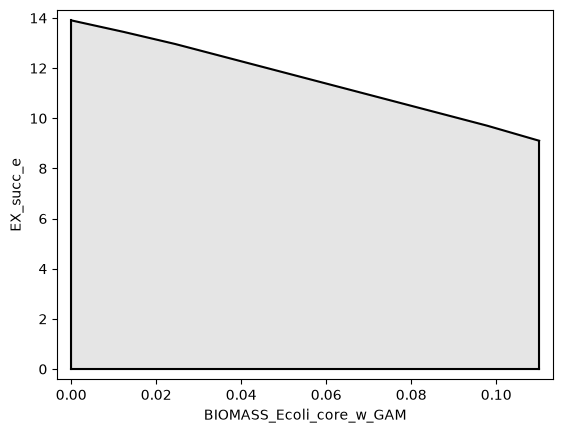

In [34]:
%matplotlib inline
from mewpy.visualization.envelope import plot_flux_envelope

plot_flux_envelope(simul,'BIOMASS_Ecoli_core_w_GAM','EX_succ_e',constraints = constraints)

`simulate` has more parameters, such as the optimization direction. Please refer to the module documentation for a full description.

## Mutant phenotypes relative to the wild type

FBA and pFBA assume that the mutant reaches its optimal growth. lMOMA and ROOM predict the mutant flux distribution closest to a wild-type reference: lMOMA minimises the sum of absolute flux changes, and ROOM the number of reactions whose flux differs from its wild-type value $w$ by more than $0.03|w| + 0.001$. The reference is the simulator's `reference`, the pFBA fluxes under its environmental conditions, unless a `reference` dictionary is passed to `simulate`. ROOM is a mixed-integer problem and takes much longer than lMOMA.

In [35]:
import pandas as pd

# wild-type reference: pFBA fluxes under the simulator's conditions
fluxes = {'wild type': simul.reference}
for method in ['pFBA', 'lMOMA', 'ROOM']:
    fluxes[method] = simul.simulate(method=method, constraints=constraints).fluxes

pd.DataFrame(fluxes).loc[['BIOMASS_Ecoli_core_w_GAM', 'EX_succ_e', 'EX_ac_e', 'EX_etoh_e', 'EX_for_e']]

,wild type,pFBA,lMOMA,ROOM
BIOMASS_Ecoli_core_w_GAM,0.211451,0.109986,0.098124,0.099988
EX_succ_e,0.000000,8.464850,0.663523,0.588217
EX_ac_e,8.428642,9.185982,8.428642,8.498305
EX_etoh_e,8.357616,0.677549,8.388226,8.578732
EX_for_e,17.653990,10.321520,17.653990,17.123370


pFBA predicts that the mutant replaces most of its ethanol secretion with succinate. lMOMA and ROOM keep acetate, ethanol and formate secretion close to the wild type, and predict much less succinate and slightly lower growth. The ROOM optimum need not be unique: other flux distributions may change the same number of reactions.

## Flux Variability Analysis

Flux Variability Analysis (FVA) computes the minimum and maximum flux of each reaction, for all reactions or for a list of reactions:

In [36]:
# all reactions
simul.FVA(format='df')

,Reaction ID,Minimum,Maximum
0,ACALD,-16.095510,-5.903510
1,ACALDt,-3.057600,0.000000
2,ACKr,-8.653227,-0.464848
3,ACONTa,0.205527,0.900436
4,ACONTb,0.205527,0.900436
...,...,...,...
90,TALA,-0.037867,0.943613
91,THD2,0.000000,7.088275
92,TKT1,-0.037867,0.943613
93,TKT2,-0.114277,0.874844


In [37]:
# succinate secretion only
simul.FVA('EX_succ_e', format='df')

,Reaction ID,Minimum,Maximum
0,EX_succ_e,0.0,1.911


By default, FVA requires the objective to be at least 90% of its optimum (`obj_frac=0.9`). With `obj_frac=0.1`, growth must be at least 10% of the optimum:

In [38]:
simul.FVA('EX_succ_e', obj_frac=0.1, format='df')

,Reaction ID,Minimum,Maximum
0,EX_succ_e,0.0,13.109517


FVA uses the simulator's environmental conditions and accepts additional constraints, such as the deletions used above to increase succinate production:

In [39]:
simul.FVA('EX_succ_e', constraints=constraints,format='df')

,Reaction ID,Minimum,Maximum
0,EX_succ_e,0.0,9.651385


## Gene and reaction essentiality

Essential reactions and genes are those whose deletion lowers growth below `min_growth` (default 0.01, in the units of the biomass flux), under the simulator's conditions, here anaerobic growth on glucose:

In [40]:
simul.essential_reactions()

  0%|          | 0/95 [00:00<?, ?it/s]

100%|██████████| 95/95 [00:00<00:00, 2308.80it/s]

['ACONTa',
 'ACONTb',
 'BIOMASS_Ecoli_core_w_GAM',
 'CS',
 'ENO',
 'EX_h_e',
 'EX_nh4_e',
 'EX_pi_e',
 'FBA',
 'GAPD',
 'GLCpts',
 'GLNS',
 'ICDHyr',
 'NH4t',
 'PFK',
 'PGI',
 'PGK',
 'PGM',
 'PIt2r',
 'PPC',
 'RPI',
 'TPI']

In [41]:
simul.essential_genes()

  0%|          | 0/137 [00:00<?, ?it/s]

100%|██████████| 137/137 [00:00<00:00, 2898.61it/s]

['b0720',
 'b2779',
 'b2415',
 'b2416',
 'b1779',
 'b1136',
 'b4025',
 'b2926',
 'b3956',
 'b3919']

## The same simulation on REFRAMED, COBRApy and GERM models

Simulators accept reaction, metabolite and gene ids with or without REFRAMED's `R_`, `M_` and `G_` prefixes, so the same conditions and constraints run on the three models. Results are keyed by each model's own ids.

In [42]:
models = {'REFRAMED': rf_model, 'COBRApy': cb_model, 'GERM': germ_model}

# ids without prefix ('GND') and with prefix ('R_PYK') are both accepted
envcond = {'EX_glc__D_e': (-10.0, 1000.0), 'EX_o2_e': (0, 0)}
deletions = {'GND': 0, 'R_PYK': 0, 'ME2': 0}

rows = {}
for name, m in models.items():
    sim = get_simulator(m, envcond=envcond)
    biomass = sim.resolve('BIOMASS_Ecoli_core_w_GAM')  # the model's own id
    wild_type = sim.simulate(method='FBA')
    mutant = sim.simulate(method='pFBA', constraints=deletions)
    rows[name] = {'biomass id': biomass,
                  'wild-type growth (FBA)': wild_type.objective_value,
                  'mutant growth (pFBA)': mutant.fluxes[biomass],
                  'mutant succinate (pFBA)': mutant.fluxes[sim.resolve('EX_succ_e')]}

pd.DataFrame(rows).T

,biomass id,wild-type growth (FBA),mutant growth (pFBA),mutant succinate (pFBA)
REFRAMED,R_BIOMASS_Ecoli_core_w_GAM,0.211663,0.109986,8.46485
COBRApy,BIOMASS_Ecoli_core_w_GAM,0.211663,0.109986,8.46485
GERM,BIOMASS_Ecoli_core_w_GAM,0.211663,0.109986,8.46485


Wild-type growth, and the mutant's pFBA growth and succinate secretion, are the same on the three models. GERM simulators run FBA and pFBA only: MOMA, lMOMA and ROOM raise `NotImplementedError`.

For more options and methods please refer to the MEWpy documentation.